# MercadoLibre | Conversion Funnel Analysis

## 1. Business Objective

This analysis examines how users progress through MercadoLibre's purchase journey and identifies the stages with the largest observed conversion losses.

### Business Questions

1. How many unique users reach each stage of the purchase funnel?
2. Where are the largest conversion drop-offs?
3. How does funnel performance vary across countries?

### Analysis Period

January 1 – August 31, 2025.

### Funnel Stages

| Stage | Event |
|---|---|
| Discovery | `first_visit` |
| Product Interest | `select_item` / `select_promotion` |
| Add to Cart | `add_to_cart` |
| Checkout | `begin_checkout` |
| Shipping Information | `add_shipping_info` |
| Payment Information | `add_payment_info` |
| Purchase | `purchase` |

### Methodology

Two complementary approaches will be used:

- **Event Reach:** Counts unique users who recorded each event during the analysis period.
- **Sequential Funnel:** Counts users who completed the required stages in chronological order.

The sequential funnel will use standardized `event_date` timestamps. Events sharing the same timestamp may have an ambiguous order.

These metrics will be interpreted separately to avoid confusing event participation with confirmed funnel progression.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd

# Database location
db_path = Path("../data/raw/tripleten.db").resolve()

# Connect to SQLite in read-only mode
connection = sqlite3.connect(
    db_path.as_uri() + "?mode=ro",
    uri=True
)

# Verify connection
query = """
SELECT
    COUNT(*) AS total_events,
    COUNT(DISTINCT user_id) AS unique_users
FROM mercadolibre_funnel
WHERE event_date >= '2025-01-01'
  AND event_date < '2025-09-01';
"""

funnel_scope = pd.read_sql_query(query, connection)

display(funnel_scope)

,total_events,unique_users
0,26695,1755


## 2. Event Reach Funnel

### 2.1 Unique Users by Funnel Stage

This analysis counts the unique users who recorded each funnel event during the selected period, regardless of event order.

It provides an initial overview of funnel participation before evaluating chronological progression.

In [4]:
# Count unique users by funnel stage

query = """
WITH funnel_events AS (
    SELECT
        user_id,
        CASE
            WHEN event_name = 'first_visit' THEN '1. first_visit'
            WHEN event_name IN ('select_item', 'select_promotion')
                THEN '2. select_item / select_promotion'
            WHEN event_name = 'add_to_cart' THEN '3. add_to_cart'
            WHEN event_name = 'begin_checkout' THEN '4. begin_checkout'
            WHEN event_name = 'add_shipping_info' THEN '5. add_shipping_info'
            WHEN event_name = 'add_payment_info' THEN '6. add_payment_info'
            WHEN event_name = 'purchase' THEN '7. purchase'
        END AS funnel_stage
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
)

SELECT
    funnel_stage,
    COUNT(DISTINCT user_id) AS unique_users
FROM funnel_events
WHERE funnel_stage IS NOT NULL
GROUP BY funnel_stage
ORDER BY funnel_stage;
"""

event_reach = pd.read_sql_query(query, connection)

display(event_reach)

,funnel_stage,unique_users
0,1. first_visit,1204
1,2. select_item / select_promotion,1309
2,3. add_to_cart,174
3,4. begin_checkout,60
4,5. add_shipping_info,40
5,6. add_payment_info,33
6,7. purchase,17


## 3. Sequential Conversion Funnel

### 3.1 Chronological User Progression

This analysis measures how users progress through the purchase funnel in chronological order.

Users must complete each preceding stage before being counted in the next stage.

The analysis uses standardized event dates and allows progression across multiple sessions within the selected period.

Events with identical timestamps are not considered evidence of chronological progression.

In [5]:
# Sequential conversion funnel using chronological events

query = """
WITH events AS (
    SELECT DISTINCT
        user_id,
        datetime(
            CASE
                WHEN substr(event_date, 12, 2) LIKE '%:'
                THEN substr(event_date, 1, 11) || '0' ||
                     substr(event_date, 12)
                ELSE event_date
            END
        ) AS event_time,
        CASE
            WHEN event_name = 'first_visit' THEN 1
            WHEN event_name IN ('select_item', 'select_promotion') THEN 2
            WHEN event_name = 'add_to_cart' THEN 3
            WHEN event_name = 'begin_checkout' THEN 4
            WHEN event_name = 'add_shipping_info' THEN 5
            WHEN event_name = 'add_payment_info' THEN 6
            WHEN event_name = 'purchase' THEN 7
        END AS stage
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
),

step_1 AS (
    SELECT user_id, MIN(event_time) AS step_time
    FROM events
    WHERE stage = 1
    GROUP BY user_id
),

step_2 AS (
    SELECT e.user_id, MIN(e.event_time) AS step_time
    FROM events e
    JOIN step_1 s ON e.user_id = s.user_id
    WHERE e.stage = 2
      AND e.event_time > s.step_time
    GROUP BY e.user_id
),

step_3 AS (
    SELECT e.user_id, MIN(e.event_time) AS step_time
    FROM events e
    JOIN step_2 s ON e.user_id = s.user_id
    WHERE e.stage = 3
      AND e.event_time > s.step_time
    GROUP BY e.user_id
),

step_4 AS (
    SELECT e.user_id, MIN(e.event_time) AS step_time
    FROM events e
    JOIN step_3 s ON e.user_id = s.user_id
    WHERE e.stage = 4
      AND e.event_time > s.step_time
    GROUP BY e.user_id
),

step_5 AS (
    SELECT e.user_id, MIN(e.event_time) AS step_time
    FROM events e
    JOIN step_4 s ON e.user_id = s.user_id
    WHERE e.stage = 5
      AND e.event_time > s.step_time
    GROUP BY e.user_id
),

step_6 AS (
    SELECT e.user_id, MIN(e.event_time) AS step_time
    FROM events e
    JOIN step_5 s ON e.user_id = s.user_id
    WHERE e.stage = 6
      AND e.event_time > s.step_time
    GROUP BY e.user_id
),

step_7 AS (
    SELECT e.user_id, MIN(e.event_time) AS step_time
    FROM events e
    JOIN step_6 s ON e.user_id = s.user_id
    WHERE e.stage = 7
      AND e.event_time > s.step_time
    GROUP BY e.user_id
)

SELECT 1 AS stage_order, 'first_visit' AS event_name,
       COUNT(*) AS unique_users FROM step_1

UNION ALL
SELECT 2, 'select_item / select_promotion', COUNT(*) FROM step_2

UNION ALL
SELECT 3, 'add_to_cart', COUNT(*) FROM step_3

UNION ALL
SELECT 4, 'begin_checkout', COUNT(*) FROM step_4

UNION ALL
SELECT 5, 'add_shipping_info', COUNT(*) FROM step_5

UNION ALL
SELECT 6, 'add_payment_info', COUNT(*) FROM step_6

UNION ALL
SELECT 7, 'purchase', COUNT(*) FROM step_7

ORDER BY stage_order;
"""

sequential_funnel = pd.read_sql_query(query, connection)

display(sequential_funnel)

,stage_order,event_name,unique_users
0,1,first_visit,1204
1,2,select_item / select_promotion,845
2,3,add_to_cart,104
3,4,begin_checkout,37
4,5,add_shipping_info,23
5,6,add_payment_info,19
6,7,purchase,11


### 3.2 Conversion and Drop-off Rates

This analysis calculates the conversion rate, drop-off rate, and number of users lost between consecutive funnel stages.

It also measures cumulative conversion from `first_visit` to each subsequent stage.

In [6]:
# Calculate sequential funnel conversion metrics

funnel_metrics = sequential_funnel.copy()

# Users from the previous stage
funnel_metrics["previous_users"] = (
    funnel_metrics["unique_users"].shift(1)
)

# Conversion rate between consecutive stages
funnel_metrics["step_conversion_pct"] = (
    funnel_metrics["unique_users"]
    / funnel_metrics["previous_users"]
    * 100
)

# Drop-off rate between consecutive stages
funnel_metrics["drop_off_pct"] = (
    100 - funnel_metrics["step_conversion_pct"]
)

# Number of users lost between stages
funnel_metrics["users_lost"] = (
    funnel_metrics["previous_users"]
    - funnel_metrics["unique_users"]
)

# Cumulative conversion from first_visit
funnel_metrics["cumulative_conversion_pct"] = (
    funnel_metrics["unique_users"]
    / funnel_metrics["unique_users"].iloc[0]
    * 100
)

# The first stage has no preceding stage
funnel_metrics.loc[0, ["step_conversion_pct", "drop_off_pct", "users_lost"]] = float("nan")

# Display results
display(
    funnel_metrics[
        [
            "event_name",
            "unique_users",
            "step_conversion_pct",
            "drop_off_pct",
            "users_lost",
            "cumulative_conversion_pct"
        ]
    ].round(2)
)

,event_name,unique_users,step_conversion_pct,drop_off_pct,users_lost,cumulative_conversion_pct
0,first_visit,1204,NaN,NaN,NaN,100.00
1,select_item / select_promotion,845,70.18,29.82,359.0,70.18
2,add_to_cart,104,12.31,87.69,741.0,8.64
3,begin_checkout,37,35.58,64.42,67.0,3.07
4,add_shipping_info,23,62.16,37.84,14.0,1.91
5,add_payment_info,19,82.61,17.39,4.0,1.58
6,purchase,11,57.89,42.11,8.0,0.91


### 3.3 Sequential Funnel Visualization

This chart shows the number of users who completed each funnel stage in chronological order.

It highlights the stages where the largest user losses occur.

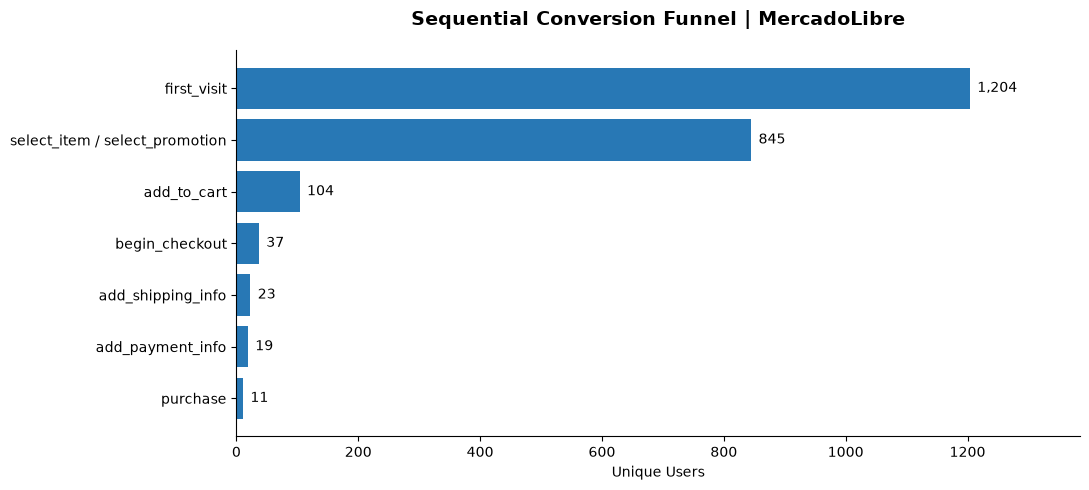

In [7]:
# Visualize the sequential conversion funnel

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    funnel_metrics["event_name"],
    funnel_metrics["unique_users"],
    color="#2878B5"
)

# Display user counts
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 12,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=10
    )

ax.invert_yaxis()

ax.set_title(
    "Sequential Conversion Funnel | MercadoLibre",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Unique Users")
ax.set_ylabel("")

ax.set_xlim(0, funnel_metrics["unique_users"].max() * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 4. Purchase Journey Validation

### 4.1 Event Coverage Among Purchasing Users

This analysis examines which funnel events were recorded by users who completed a purchase.

It helps identify potentially missing or skipped stages and explains differences between total purchasers and strict sequential funnel conversions.

In [8]:
# Analyze event coverage among purchasing users

query = """
WITH period_events AS (
    SELECT DISTINCT
        user_id,
        event_name
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
),

purchasers AS (
    SELECT DISTINCT user_id
    FROM period_events
    WHERE event_name = 'purchase'
),

purchase_journeys AS (
    SELECT
        p.user_id,
        MAX(CASE WHEN e.event_name = 'first_visit'
            THEN 1 ELSE 0 END) AS first_visit,
        MAX(CASE WHEN e.event_name IN ('select_item', 'select_promotion')
            THEN 1 ELSE 0 END) AS product_selection,
        MAX(CASE WHEN e.event_name = 'add_to_cart'
            THEN 1 ELSE 0 END) AS add_to_cart,
        MAX(CASE WHEN e.event_name = 'begin_checkout'
            THEN 1 ELSE 0 END) AS begin_checkout,
        MAX(CASE WHEN e.event_name = 'add_shipping_info'
            THEN 1 ELSE 0 END) AS add_shipping_info,
        MAX(CASE WHEN e.event_name = 'add_payment_info'
            THEN 1 ELSE 0 END) AS add_payment_info
    FROM purchasers p
    LEFT JOIN period_events e
        ON p.user_id = e.user_id
    GROUP BY p.user_id
)

SELECT
    COUNT(*) AS total_purchasers,
    SUM(first_visit) AS with_first_visit,
    SUM(product_selection) AS with_product_selection,
    SUM(add_to_cart) AS with_add_to_cart,
    SUM(begin_checkout) AS with_begin_checkout,
    SUM(add_shipping_info) AS with_shipping_info,
    SUM(add_payment_info) AS with_payment_info,
    SUM(
        CASE
            WHEN first_visit = 1
             AND product_selection = 1
             AND add_to_cart = 1
             AND begin_checkout = 1
             AND add_shipping_info = 1
             AND add_payment_info = 1
            THEN 1 ELSE 0
        END
    ) AS with_all_stages

FROM purchase_journeys;
"""

purchase_journey_validation = pd.read_sql_query(query, connection)

display(purchase_journey_validation)

,total_purchasers,with_first_visit,with_product_selection,with_add_to_cart,with_begin_checkout,with_shipping_info,with_payment_info,with_all_stages
0,17,15,17,17,17,17,17,15


### 4.2 Purchase Event Chronology

This analysis compares the timing of purchase events with the preceding funnel stages.

The goal is to identify chronological inconsistencies and understand why some purchasers are excluded from the strict sequential funnel.

In [9]:
# Compare purchase timing with previous funnel events

query = """
WITH events AS (
    SELECT
        user_id,
        event_name,
        datetime(
            CASE
                WHEN substr(event_date, 12, 2) LIKE '%:'
                THEN substr(event_date, 1, 11) || '0' ||
                     substr(event_date, 12)
                ELSE event_date
            END
        ) AS event_time
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
),

purchaser_events AS (
    SELECT
        user_id,
        MIN(CASE WHEN event_name = 'first_visit'
            THEN event_time END) AS first_visit_time,
        MIN(CASE WHEN event_name = 'add_to_cart'
            THEN event_time END) AS cart_time,
        MIN(CASE WHEN event_name = 'add_payment_info'
            THEN event_time END) AS payment_time,
        MIN(CASE WHEN event_name = 'purchase'
            THEN event_time END) AS purchase_time
    FROM events
    GROUP BY user_id
)

SELECT
    COUNT(*) AS total_purchasers,

    SUM(CASE WHEN first_visit_time IS NULL
        THEN 1 ELSE 0 END) AS missing_first_visit,

    SUM(CASE WHEN cart_time >= purchase_time
        THEN 1 ELSE 0 END) AS cart_not_before_purchase,

    SUM(CASE WHEN payment_time >= purchase_time
        THEN 1 ELSE 0 END) AS payment_not_before_purchase

FROM purchaser_events
WHERE purchase_time IS NOT NULL;
"""

purchase_chronology = pd.read_sql_query(query, connection)

display(purchase_chronology)

,total_purchasers,missing_first_visit,cart_not_before_purchase,payment_not_before_purchase
0,17,2,0,0


### 4.3 Intermediate Stage Chronology

This analysis checks the order of the first recorded funnel events among purchasing users.

It helps identify potential differences between event coverage and chronological funnel completion.

In [10]:
# Check the order of intermediate funnel stages

query = """
WITH events AS (
    SELECT
        user_id,
        event_name,
        datetime(
            CASE
                WHEN substr(event_date, 12, 2) LIKE '%:'
                THEN substr(event_date, 1, 11) || '0' ||
                     substr(event_date, 12)
                ELSE event_date
            END
        ) AS event_time
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
),

purchaser_stages AS (
    SELECT
        user_id,

        MIN(CASE WHEN event_name = 'first_visit'
            THEN event_time END) AS first_visit_time,

        MIN(CASE WHEN event_name IN ('select_item', 'select_promotion')
            THEN event_time END) AS selection_time,

        MIN(CASE WHEN event_name = 'add_to_cart'
            THEN event_time END) AS cart_time,

        MIN(CASE WHEN event_name = 'begin_checkout'
            THEN event_time END) AS checkout_time,

        MIN(CASE WHEN event_name = 'add_shipping_info'
            THEN event_time END) AS shipping_time,

        MIN(CASE WHEN event_name = 'add_payment_info'
            THEN event_time END) AS payment_time,

        MIN(CASE WHEN event_name = 'purchase'
            THEN event_time END) AS purchase_time

    FROM events
    GROUP BY user_id
)

SELECT
    COUNT(*) AS purchasers_with_all_stages,

    SUM(CASE WHEN selection_time <= first_visit_time
        THEN 1 ELSE 0 END) AS selection_not_after_first_visit,

    SUM(CASE WHEN cart_time <= selection_time
        THEN 1 ELSE 0 END) AS cart_not_after_selection,

    SUM(CASE WHEN checkout_time <= cart_time
        THEN 1 ELSE 0 END) AS checkout_not_after_cart,

    SUM(CASE WHEN shipping_time <= checkout_time
        THEN 1 ELSE 0 END) AS shipping_not_after_checkout,

    SUM(CASE WHEN payment_time <= shipping_time
        THEN 1 ELSE 0 END) AS payment_not_after_shipping,

    SUM(CASE WHEN purchase_time <= payment_time
        THEN 1 ELSE 0 END) AS purchase_not_after_payment

FROM purchaser_stages
WHERE purchase_time IS NOT NULL
  AND first_visit_time IS NOT NULL
  AND selection_time IS NOT NULL
  AND cart_time IS NOT NULL
  AND checkout_time IS NOT NULL
  AND shipping_time IS NOT NULL
  AND payment_time IS NOT NULL;
"""

stage_chronology = pd.read_sql_query(query, connection)

display(stage_chronology)

,purchasers_with_all_stages,selection_not_after_first_visit,cart_not_after_selection,checkout_not_after_cart,shipping_not_after_checkout,payment_not_after_shipping,purchase_not_after_payment
0,15,7,0,0,0,0,0


### 4.4 Sequential Funnel Exclusions

This analysis identifies where purchasers with all funnel events stopped progressing through the required chronological sequence.

The goal is to explain the difference between purchasers with complete event coverage and those who completed the strict sequential funnel.

In [11]:
# Identify where purchasers fail the strict chronological funnel

query = """
WITH RECURSIVE

events AS (
    SELECT DISTINCT
        user_id,
        datetime(
            CASE
                WHEN substr(event_date, 12, 2) LIKE '%:'
                THEN substr(event_date, 1, 11) || '0' ||
                     substr(event_date, 12)
                ELSE event_date
            END
        ) AS event_time,
        CASE
            WHEN event_name = 'first_visit' THEN 1
            WHEN event_name IN ('select_item', 'select_promotion') THEN 2
            WHEN event_name = 'add_to_cart' THEN 3
            WHEN event_name = 'begin_checkout' THEN 4
            WHEN event_name = 'add_shipping_info' THEN 5
            WHEN event_name = 'add_payment_info' THEN 6
            WHEN event_name = 'purchase' THEN 7
        END AS stage
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
),

eligible_purchasers AS (
    SELECT user_id
    FROM events
    WHERE stage IS NOT NULL
    GROUP BY user_id
    HAVING COUNT(DISTINCT stage) = 7
),

ordered_events AS (
    SELECT
        e.user_id,
        e.event_time,
        e.stage,
        ROW_NUMBER() OVER (
            PARTITION BY e.user_id
            ORDER BY e.event_time, e.stage
        ) AS event_order
    FROM events e
    JOIN eligible_purchasers p
        ON e.user_id = p.user_id
    WHERE e.stage IS NOT NULL
),

progress AS (
    SELECT
        user_id,
        0 AS event_order,
        0 AS stage_reached,
        NULL AS last_stage_time
    FROM eligible_purchasers

    UNION ALL

    SELECT
        e.user_id,
        e.event_order,

        CASE
            WHEN e.stage = p.stage_reached + 1
             AND (
                 p.last_stage_time IS NULL
                 OR e.event_time > p.last_stage_time
             )
            THEN p.stage_reached + 1
            ELSE p.stage_reached
        END,

        CASE
            WHEN e.stage = p.stage_reached + 1
             AND (
                 p.last_stage_time IS NULL
                 OR e.event_time > p.last_stage_time
             )
            THEN e.event_time
            ELSE p.last_stage_time
        END

    FROM progress p
    JOIN ordered_events e
        ON e.user_id = p.user_id
       AND e.event_order = p.event_order + 1
),

final_progress AS (
    SELECT
        user_id,
        MAX(stage_reached) AS stage_reached
    FROM progress
    GROUP BY user_id
)

SELECT
    CASE stage_reached
        WHEN 0 THEN 'first_visit'
        WHEN 1 THEN 'select_item / select_promotion'
        WHEN 2 THEN 'add_to_cart'
        WHEN 3 THEN 'begin_checkout'
        WHEN 4 THEN 'add_shipping_info'
        WHEN 5 THEN 'add_payment_info'
        WHEN 6 THEN 'purchase'
        WHEN 7 THEN 'Completed all stages'
    END AS next_required_stage,

    COUNT(*) AS purchasers

FROM final_progress
GROUP BY stage_reached
ORDER BY stage_reached;
"""

purchase_exclusions = pd.read_sql_query(query, connection)

display(purchase_exclusions)

,next_required_stage,purchasers
0,add_to_cart,4
1,Completed all stages,11


## 5. Geographic Funnel Analysis

### 5.1 First Visits and Purchases by Country

This analysis compares the number of unique users who recorded `first_visit` and `purchase` events across countries.

These counts provide an initial overview of geographic differences before calculating conversion rates.

In [12]:
# Compare first visits and purchases by country

query = """
SELECT
    country,

    COUNT(DISTINCT CASE
        WHEN event_name = 'first_visit'
        THEN user_id
    END) AS first_visit_users,

    COUNT(DISTINCT CASE
        WHEN event_name = 'purchase'
        THEN user_id
    END) AS purchase_users

FROM mercadolibre_funnel

WHERE event_date >= '2025-01-01'
  AND event_date < '2025-09-01'

GROUP BY country

ORDER BY first_visit_users DESC;
"""

country_funnel = pd.read_sql_query(query, connection)

display(country_funnel)

,country,first_visit_users,purchase_users
0,Brazil,292,3
1,Mexico,245,7
2,Colombia,166,0
3,Argentina,160,2
4,Peru,110,2
5,Chile,98,1
6,Ecuador,59,0
7,Bolivia,31,1
8,Uruguay,22,1
9,Paraguay,21,0


### 5.2 First-Visit-to-Purchase Conversion by Country

This analysis measures the percentage of users who recorded a purchase after their first visit during the analysis period.

Users are assigned to the country of their first recorded visit.

Unlike the strict sequential funnel, this metric does not require users to complete every intermediate stage.

In [13]:
# Calculate first-visit-to-purchase conversion by country

query = """
WITH events AS (
    SELECT
        user_id,
        country,
        event_name,
        datetime(
            CASE
                WHEN substr(event_date, 12, 2) LIKE '%:'
                THEN substr(event_date, 1, 11) || '0' ||
                     substr(event_date, 12)
                ELSE event_date
            END
        ) AS event_time
    FROM mercadolibre_funnel
    WHERE event_date >= '2025-01-01'
      AND event_date < '2025-09-01'
),

first_visits AS (
    SELECT
        user_id,
        country,
        event_time AS first_visit_time,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY event_time, country
        ) AS visit_order
    FROM events
    WHERE event_name = 'first_visit'
),

visitor_conversion AS (
    SELECT
        fv.user_id,
        fv.country,
        MAX(
            CASE
                WHEN e.event_name = 'purchase'
                 AND e.event_time > fv.first_visit_time
                THEN 1 ELSE 0
            END
        ) AS converted
    FROM first_visits fv
    LEFT JOIN events e
        ON fv.user_id = e.user_id
    WHERE fv.visit_order = 1
    GROUP BY fv.user_id, fv.country
)

SELECT
    country,
    COUNT(*) AS first_visit_users,
    SUM(converted) AS converted_users,
    ROUND(
        100.0 * SUM(converted) / COUNT(*),
        2
    ) AS conversion_rate_pct
FROM visitor_conversion
GROUP BY country
ORDER BY conversion_rate_pct DESC;
"""

country_conversion = pd.read_sql_query(query, connection)

display(country_conversion)

,country,first_visit_users,converted_users,conversion_rate_pct
0,Uruguay,22,1,4.55
1,Bolivia,31,1,3.23
2,Peru,110,2,1.82
3,Mexico,245,4,1.63
4,Brazil,292,2,0.68
5,Argentina,160,1,0.63
6,Paraguay,21,0,0.00
7,Ecuador,59,0,0.00
8,Colombia,166,0,0.00
9,Chile,98,0,0.00


### 5.3 Geographic Conversion Visualization

This chart compares first-visit-to-purchase conversion rates across countries.

Conversion rates are descriptive and should be interpreted cautiously due to the small number of purchases.

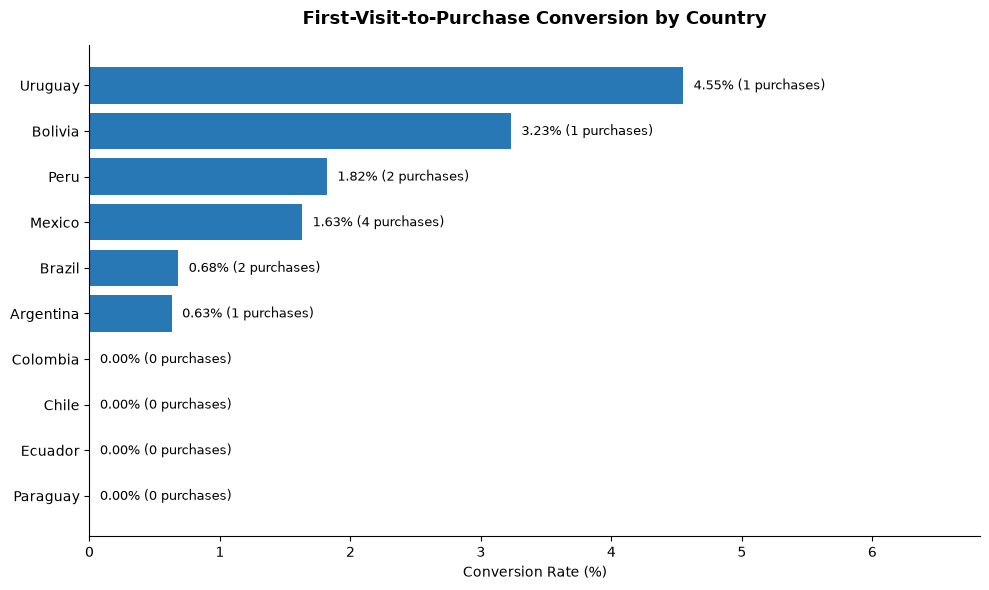

In [14]:
# Visualize conversion rates by country

import matplotlib.pyplot as plt

country_plot = country_conversion.sort_values(
    "conversion_rate_pct",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    country_plot["country"],
    country_plot["conversion_rate_pct"],
    color="#2878B5"
)

# Add conversion rates and purchaser counts
for bar, purchases in zip(
    bars,
    country_plot["converted_users"]
):
    width = bar.get_width()

    ax.text(
        width + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}% ({purchases} purchases)",
        va="center",
        fontsize=9
    )

ax.set_title(
    "First-Visit-to-Purchase Conversion by Country",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Conversion Rate (%)")
ax.set_ylabel("")

ax.set_xlim(
    0,
    country_plot["conversion_rate_pct"].max() * 1.5
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 6. Key Findings and Business Recommendations

### 6.1 Key Findings

**1. The largest drop-off occurs between product selection and cart addition.**

Of the 845 users who reached `select_item / select_promotion` in the sequential funnel, only 104 progressed to `add_to_cart`.

This represents an observed drop-off of **87.69%**, equivalent to 741 users.

**2. Checkout initiation is another critical stage.**

Of the 104 users who reached `add_to_cart`, only 37 progressed to `begin_checkout`, representing a **64.42% drop-off**.

**3. Strict sequential funnel conversion is 0.91%.**

Of the 1,204 users who recorded `first_visit`, 11 completed all seven funnel stages in chronological order.

This metric should not be interpreted as the platform's overall purchase conversion rate.

**4. Purchase journey validation reveals differences in event coverage and chronology.**

- 17 users recorded `purchase`.
- 15 recorded all seven funnel stages, regardless of order.
- 11 completed the full chronological sequence.

Among the four purchasers excluded despite having complete event coverage, the next required stage was `add_to_cart`. Their cart events were recorded but did not satisfy the required chronological sequence.

**5. Geographic conversion rates vary, but purchase volumes are limited.**

Uruguay recorded the highest observed first-visit-to-purchase conversion rate (4.55%), based on one purchase among 22 users.

Mexico recorded the largest number of converted users in this cohort (4).

The small number of purchases limits the reliability of country-level comparisons.

### 6.2 Business Recommendations

**Prioritize the product selection-to-cart transition.**

Investigate product information, pricing, shipping expectations, and the usability of the add-to-cart process to understand why relatively few users progress.

**Review the checkout experience.**

Evaluate possible friction between cart addition and checkout initiation, including unexpected costs and navigation difficulties.

**Improve funnel measurement.**

Validate event tracking and the consistency of user journeys to distinguish genuine abandonment from missing, repeated, or out-of-order events.

**Monitor geographic performance.**

Continue tracking conversion by country, but avoid making major market-level decisions based on the small number of observed purchases.

### 6.3 Analysis Limitations

- The analysis covers January 1 to August 31, 2025.
- The sequential funnel requires all seven stages in chronological order and allows progression across sessions.
- The analysis uses standardized `event_date` values because `event_times` has limited precision.
- Users who skip stages or have events outside the observation period may be excluded from strict funnel conversion.
- Observed drop-offs do not necessarily represent confirmed purchase abandonment.
- The dataset contains a limited number of purchases, especially within individual countries.

### 6.4 Conclusion

The strongest opportunity for further investigation is the transition from product selection to cart addition.

The results also suggest that improving checkout usability and event tracking could help better understand user behavior.

These findings provide a starting point for targeted investigation and experimentation, rather than definitive evidence of the causes of conversion losses.